# Segundo avance – Análisis exploratorio, modelado y resultados preliminares
## Predicción del nivel de riesgo cardíaco (Bajo / Medio / Alto) mediante clasificación multiclase

**Universidad de la Costa – CUC** · Minería de Datos · Grupo VIRTUAL-25786 · Profesor: José Escorcia Gutiérrez
**Integrante(s):** Sebastián Andrés Muñoz Lemus 

| Elemento | Detalle |
|---|---|
| **Tipo de proyecto** | Clasificación supervisada **multiclase** (3 clases ordinales) |
| **Pregunta** | ¿Es posible predecir el nivel de riesgo cardíaco (Bajo, Medio o Alto) a partir de variables demográficas y clínicas básicas, y cuál de los dos modelos comparados (regresión logística o árbol de decisión) lo hace de forma más adecuada, con especial atención a los errores sobre la clase Alto? |
| **Dataset** | Heart Failure Prediction Dataset (`heart.csv`), 918 filas × 12 columnas |
| **Fuente / descarga** | Kaggle, *fedesoriano* – <https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction> |
| **Descripción** | Registros de pacientes con 11 variables demográficas, clínicas y de prueba de esfuerzo y un diagnóstico binario (`HeartDisease`). Combina varias bases clínicas. |
| **Variable objetivo** | `nivel_riesgo` (Bajo / Medio / Alto), **construida por el grupo** a partir del dataset (ver sección 3) |

### Continuidad con el primer avance y cambios realizados
* **Dataset:** se usa `heart.csv` (el notebook previo dependía de un CSV de diabetes y, si no lo hallaba, generaba datos sintéticos; esto se eliminó).
* **Tipo de tarea:** el problema pasa de **binario a multiclase**. El dataset no trae una columna de riesgo, por lo que se construyó `nivel_riesgo` con una regla documentada y explícita.
* **Modelos:** se comparan **regresión logística** y **árbol de decisión**. La profundidad del árbol se elige solo con validación cruzada sobre el entrenamiento; la prueba se reserva para la evaluación final.
* **Limpieza:** se corrigieron celdas duplicadas, se trataron como faltantes los ceros imposibles y la imputación se hace dentro del pipeline.

## 1. Configuración e importación de librerías

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
ORDEN = ["Bajo", "Medio", "Alto"]
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Carga y preparación de los datos *(1.2)*

In [2]:
DATA_PATH = "heart.csv"   # debe estar en la misma carpeta que este notebook
try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    raise FileNotFoundError(f"No se encontró '{DATA_PATH}'. Descárgalo de Kaggle (enlace arriba) y colócalo junto al notebook.")

print(f"Filas: {df.shape[0]}, columnas: {df.shape[1]}")
print("Nulos totales:", int(df.isnull().sum().sum()), "| Duplicados:", int(df.duplicated().sum()))
print(df.dtypes.to_string())

Filas: 918, columnas: 12
Nulos totales: 0 | Duplicados: 0
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64


In [3]:
# Datos inconsistentes: valores imposibles desde el punto de vista clínico
print("Colesterol = 0 :", (df["Cholesterol"] == 0).sum(), "registros")
print("RestingBP = 0  :", (df["RestingBP"] == 0).sum(), "registro(s)")
print("Oldpeak < 0    :", (df["Oldpeak"] < 0).sum(), "registros (clínicamente posible)")
print("\nCategorías:")
for col in ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]:
    print(f"  {col:15s}", df[col].value_counts().to_dict())

Colesterol = 0 : 172 registros
RestingBP = 0  : 1 registro(s)
Oldpeak < 0    : 13 registros (clínicamente posible)

Categorías:
  Sex             {'M': 725, 'F': 193}
  ChestPainType   {'ASY': 496, 'NAP': 203, 'ATA': 173, 'TA': 46}
  RestingECG      {'Normal': 552, 'LVH': 188, 'ST': 178}
  ExerciseAngina  {'N': 547, 'Y': 371}
  ST_Slope        {'Flat': 460, 'Up': 395, 'Down': 63}


In [4]:
# Posibles valores atípicos (regla IQR; se excluyen los ceros imposibles)
filas = []
for col in ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]:
    s = df[col][df[col] > 0] if col in ["RestingBP", "Cholesterol"] else df[col]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    filas.append({"variable": col, "min": s.min(), "max": s.max(), "límite inf.": round(li, 1),
                  "límite sup.": round(ls, 1), "n atípicos": int(((s < li) | (s > ls)).sum())})
pd.DataFrame(filas).set_index("variable")

,min,max,límite inf.,límite sup.,n atípicos
variable,,,,,
Age,28.0,77.0,27.5,79.5,0
RestingBP,80.0,200.0,90.0,170.0,27
Cholesterol,85.0,603.0,105.6,376.6,23
MaxHR,60.0,202.0,66.0,210.0,2
Oldpeak,-2.6,6.2,-2.2,3.8,16


**Decisiones de preparación**
* No hay `NaN` ni duplicados, pero los faltantes están **ocultos como ceros**: 172 en `Cholesterol` y 1 en `RestingBP` (imposibles biológicamente). Se convierten a `NaN` y se **imputan con la mediana dentro del pipeline**, solo con datos de entrenamiento (evita fuga de información).
* Los atípicos (presión, colesterol, `Oldpeak`, frecuencia máxima) son clínicamente posibles y pueden corresponder a los pacientes de mayor riesgo: **se conservan**.
* `Oldpeak` negativo (13 registros) es plausible: se conserva.
* No hay identificadores ni columnas constantes.

In [5]:
df_limpio = df.copy()
df_limpio = df_limpio.rename(columns={
    "Age": "age", "Sex": "sex", "ChestPainType": "chest_pain_type", "RestingBP": "resting_bp",
    "Cholesterol": "cholesterol", "FastingBS": "fasting_bs", "RestingECG": "resting_ecg",
    "MaxHR": "max_hr", "ExerciseAngina": "exercise_angina", "Oldpeak": "oldpeak",
    "ST_Slope": "st_slope", "HeartDisease": "heart_disease"})
df_limpio = df_limpio.drop_duplicates()

df_limpio["cholesterol_missing"] = (df_limpio["cholesterol"] == 0).astype(int)   # solo para el EDA
df_limpio["cholesterol"] = df_limpio["cholesterol"].replace(0, np.nan)
df_limpio["resting_bp"] = df_limpio["resting_bp"].replace(0, np.nan)

df_limpio["sex"] = df_limpio["sex"].map({"M": "male", "F": "female"})
df_limpio["chest_pain_type"] = df_limpio["chest_pain_type"].map(
    {"TA": "typical_angina", "ATA": "atypical_angina", "NAP": "non_anginal", "ASY": "asymptomatic"})
df_limpio["resting_ecg"] = df_limpio["resting_ecg"].map({"Normal": "normal", "ST": "st_t_abnormality", "LVH": "lvh"})
df_limpio["exercise_angina"] = df_limpio["exercise_angina"].map({"N": "no", "Y": "yes"})
df_limpio["st_slope"] = df_limpio["st_slope"].map({"Up": "up", "Flat": "flat", "Down": "down"})

print("Dimensiones:", df_limpio.shape)
print("Nulos restantes:\n", df_limpio.isnull().sum()[lambda s: s > 0].to_string())

Dimensiones: (918, 13)
Nulos restantes:
 resting_bp       1
cholesterol    172


## 3. Construcción de la variable objetivo `nivel_riesgo`

`heart.csv` solo trae un diagnóstico binario (`heart_disease`). Para plantear un problema multiclase se construyó un **nivel de riesgo ordinal** combinando ese diagnóstico con tres hallazgos de alerta de la prueba de esfuerzo:

* Alerta 1: angina inducida por ejercicio (`exercise_angina = yes`).
* Alerta 2: pendiente ST no ascendente (`st_slope` ≠ `up`).
* Alerta 3: depresión ST marcada (`oldpeak` ≥ 1).

| Nivel | Regla |
|---|---|
| **Alto** | `heart_disease = 1` y **2 o más** alertas |
| **Bajo** | `heart_disease = 0` y **0 o 1** alertas |
| **Medio** | resto: diagnóstico positivo con 0–1 alertas, o diagnóstico negativo con 2–3 alertas |

> **Advertencia (fuga de información conceptual).** Es una etiqueta *construida*, no un riesgo clínico validado: sus umbrales son una decisión del grupo. Como se deriva de `heart_disease`, `exercise_angina`, `st_slope` y `oldpeak`, **esas cuatro variables se excluyen de los predictores**; de lo contrario el modelo solo reconstruiría la regla. En la sección 7 se mide cuánto inflaría el rendimiento incluirlas.

In [6]:
alertas = ((df_limpio["exercise_angina"] == "yes").astype(int)
           + (df_limpio["st_slope"] != "up").astype(int)
           + (df_limpio["oldpeak"] >= 1).astype(int))
df_limpio["n_alertas"] = alertas

df_limpio["nivel_riesgo"] = np.select(
    [(df_limpio["heart_disease"] == 1) & (alertas >= 2),
     (df_limpio["heart_disease"] == 0) & (alertas <= 1)],
    ["Alto", "Bajo"], default="Medio")
df_limpio["nivel_riesgo"] = pd.Categorical(df_limpio["nivel_riesgo"], categories=ORDEN, ordered=True)

print(pd.crosstab(df_limpio["heart_disease"], df_limpio["n_alertas"], margins=True))
print()
pd.DataFrame({"n": df_limpio["nivel_riesgo"].value_counts().reindex(ORDEN),
              "%": (df_limpio["nivel_riesgo"].value_counts(normalize=True).reindex(ORDEN) * 100).round(1)})

n_alertas        0    1    2    3  All
heart_disease                         
0              265   75   47   23  410
1               31  107  142  228  508
All            296  182  189  251  918



,n,%
nivel_riesgo,,
Bajo,340,37.0
Medio,208,22.7
Alto,370,40.3


## 4. Análisis exploratorio de datos (EDA) *(1.3)*

Las asociaciones descritas **no son causales**. Como el nivel de riesgo se construyó con `exercise_angina`, `st_slope` y `oldpeak`, su relación con la etiqueta es en parte **por diseño**; el análisis se centra en las variables que **no** intervienen en la regla.

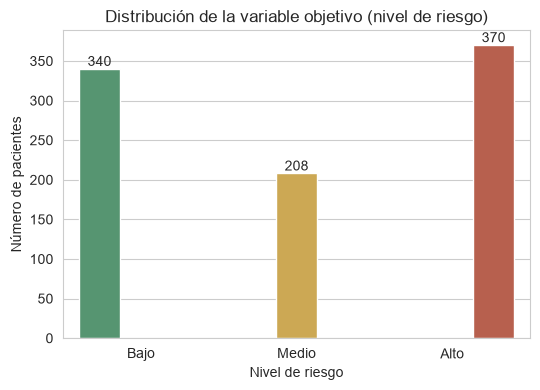

In [7]:
# Gráfico 1: distribución de la variable objetivo
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.countplot(data=df_limpio, x="nivel_riesgo", order=ORDEN, hue="nivel_riesgo",
              palette=["#4C9F70", "#E0B040", "#C8553D"], legend=False, ax=ax)
ax.set_title("Distribución de la variable objetivo (nivel de riesgo)")
ax.set_xlabel("Nivel de riesgo"); ax.set_ylabel("Número de pacientes")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

**Interpretación.** El nivel de riesgo queda distribuido en 340 pacientes Bajo (37,0 %), 208 Medio (22,7 %) y 370 Alto (40,3 %). Hay un desbalance moderado: la clase Medio es la menos frecuente, por lo que se usa **partición estratificada** y métricas **macro** y por clase, no solo el *accuracy*. Un clasificador que predijera siempre «Alto» acertaría ~40 %, que sirve de referencia mínima.

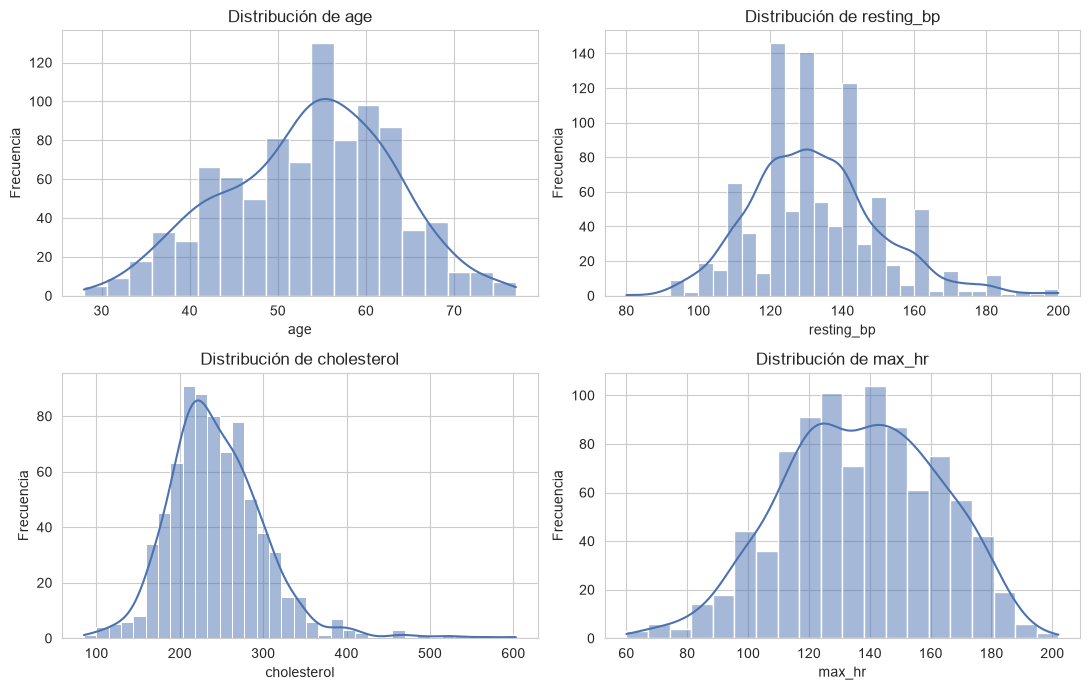

In [8]:
# Gráfico 2: distribución de variables numéricas (predictoras)
num_cols = ["age", "resting_bp", "cholesterol", "max_hr"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df_limpio[col].dropna(), kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribución de {col}"); ax.set_ylabel("Frecuencia")
plt.tight_layout(); plt.show()

**Interpretación.** `age` y `max_hr` tienen distribuciones aproximadamente simétricas; `resting_bp` y `cholesterol` muestran cola derecha por valores altos. Estas escalas y asimetrías justifican estandarizar para la regresión logística y probar un árbol, que no depende de la escala.

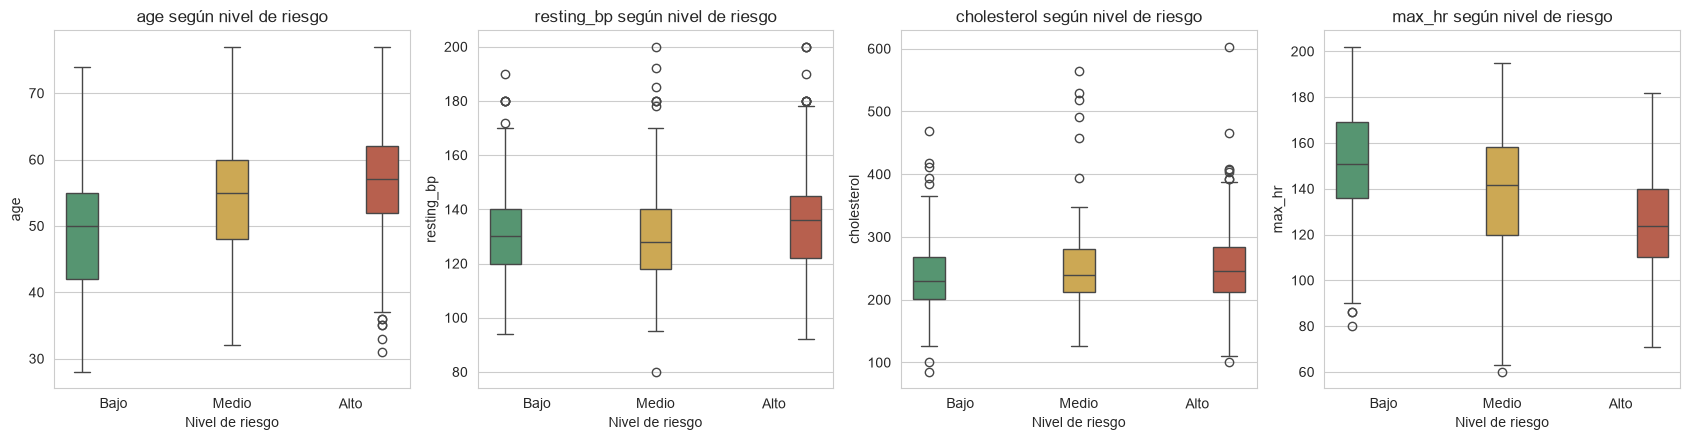

age        resting_bp        cholesterol        max_hr       
              mean median       mean median        mean median   mean median
nivel_riesgo                                                                
Bajo          49.7   50.0      130.3  130.0       236.3  230.0  149.9  151.0
Medio         54.4   55.0      129.8  128.0       252.9  240.0  137.9  141.5
Alto          56.6   57.0      136.2  136.0       250.2  246.0  124.1  123.5

In [9]:
# Gráfico 3: variables numéricas según nivel de riesgo
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_limpio, x="nivel_riesgo", y=col, order=ORDEN, hue="nivel_riesgo",
                palette=["#4C9F70", "#E0B040", "#C8553D"], legend=False, ax=ax)
    ax.set_title(f"{col} según nivel de riesgo"); ax.set_xlabel("Nivel de riesgo")
plt.tight_layout(); plt.show()
df_limpio.groupby("nivel_riesgo", observed=True)[num_cols].agg(["mean", "median"]).round(1)

**Interpretación.** De Bajo a Alto la **edad mediana sube** (50 → 55 → 57 años) y la **frecuencia cardíaca máxima baja** (mediana 151 → 141,5 → 123,5). La presión en reposo solo se eleva en Alto (mediana 136 frente a 130 y 128), y el colesterol es menor en Bajo (mediana 230) que en Medio y Alto (240 y 246), que casi no se distinguen entre sí. Estas variables no intervienen en la regla de construcción, así que la asociación no es por diseño.

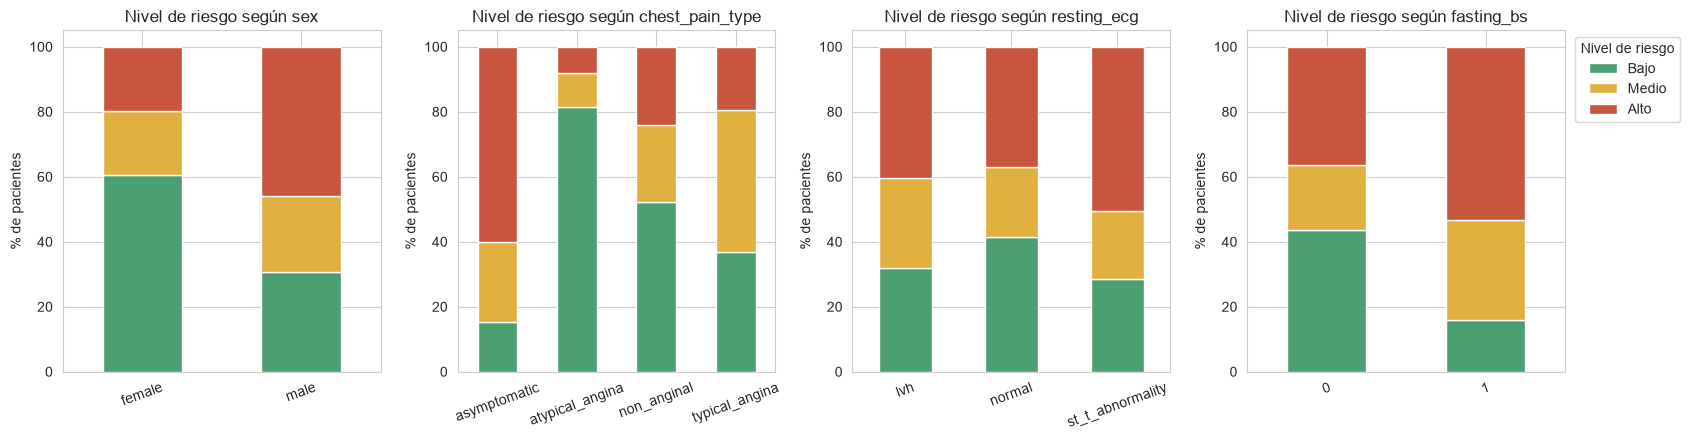

nivel_riesgo  Bajo  Medio  Alto
sex                            
female        60.6   19.7  19.7
male          30.8   23.4  45.8
nivel_riesgo     Bajo  Medio  Alto
chest_pain_type                   
asymptomatic     15.3   24.6  60.1
atypical_angina  81.5   10.4   8.1
non_anginal      52.2   23.6  24.1
typical_angina   37.0   43.5  19.6


In [10]:
# Gráfico 4: composición del nivel de riesgo por categoría de las variables categóricas predictoras
cat_cols = ["sex", "chest_pain_type", "resting_ecg", "fasting_bs"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, col in zip(axes, cat_cols):
    prop = pd.crosstab(df_limpio[col], df_limpio["nivel_riesgo"], normalize="index")[ORDEN] * 100
    prop.plot(kind="bar", stacked=True, ax=ax, color=["#4C9F70", "#E0B040", "#C8553D"], legend=False)
    ax.set_title(f"Nivel de riesgo según {col}"); ax.set_ylabel("% de pacientes"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
axes[-1].legend(title="Nivel de riesgo", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
print((pd.crosstab(df_limpio["sex"], df_limpio["nivel_riesgo"], normalize="index")[ORDEN] * 100).round(1))
print((pd.crosstab(df_limpio["chest_pain_type"], df_limpio["nivel_riesgo"], normalize="index")[ORDEN] * 100).round(1))

**Interpretación.** El **dolor torácico asintomático** concentra la mayor proporción de riesgo Alto (60,1 %), mientras que la **angina atípica** es sobre todo Bajo (81,5 %); la angina típica tiene la mayor proporción de Medio (43,5 %). Por sexo, el 45,8 % de los hombres es Alto frente al 19,7 % de las mujeres (60,6 % de ellas es Bajo). Cuidado: hay 725 hombres y solo 193 mujeres, por lo que la estimación femenina es menos precisa. Son asociaciones, no causas.

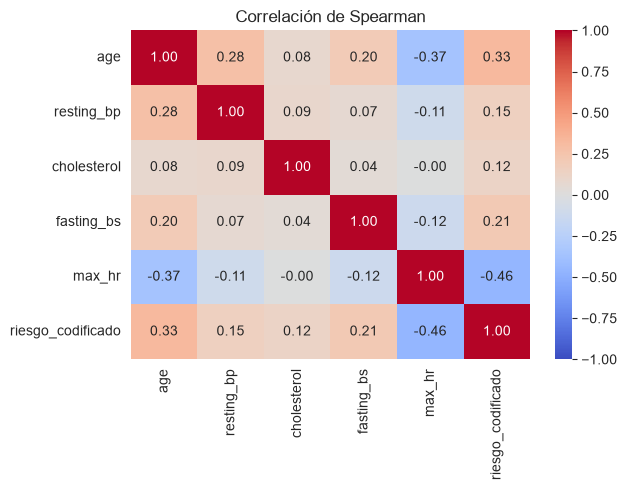

age            0.33
resting_bp     0.15
cholesterol    0.12
fasting_bs     0.21
max_hr        -0.46
Name: riesgo_codificado, dtype: float64

In [11]:
# Gráfico 5: correlación de Spearman (riesgo codificado 0/1/2 SOLO para este gráfico)
tmp = df_limpio[["age", "resting_bp", "cholesterol", "fasting_bs", "max_hr"]].copy()
tmp["riesgo_codificado"] = df_limpio["nivel_riesgo"].cat.codes
corr = tmp.corr(method="spearman")
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Spearman"); plt.tight_layout(); plt.show()
corr["riesgo_codificado"].drop("riesgo_codificado").round(2)

**Interpretación.** Con el riesgo codificado como 0/1/2, la asociación más fuerte es con `max_hr` (ρ = −0,46), seguida de `age` (+0,33) y `fasting_bs` (+0,21); `resting_bp` (+0,15) y `cholesterol` (+0,12) son débiles. Ninguna asociación es alta, lo que anticipa un problema de predicción difícil con solo estas ocho variables. Spearman es apropiado porque el riesgo es ordinal.

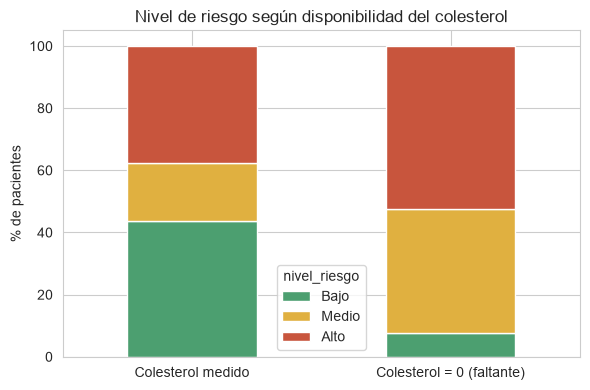

nivel_riesgo,Bajo,Medio,Alto
Colesterol medido,43.8,18.6,37.5
Colesterol = 0 (faltante),7.6,40.1,52.3


In [12]:
# Gráfico 6: colesterol faltante (0 original) y nivel de riesgo
prop = pd.crosstab(df_limpio["cholesterol_missing"], df_limpio["nivel_riesgo"], normalize="index")[ORDEN] * 100
prop.index = ["Colesterol medido", "Colesterol = 0 (faltante)"]
ax = prop.plot(kind="bar", stacked=True, color=["#4C9F70", "#E0B040", "#C8553D"], figsize=(6, 4))
ax.set_ylabel("% de pacientes"); ax.set_title("Nivel de riesgo según disponibilidad del colesterol")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
prop.round(1)

**Interpretación.** El colesterol faltante **no es aleatorio**: entre los registros con colesterol = 0, el 52,3 % es Alto y el 40,1 % Medio (solo 7,6 % Bajo), frente a 37,5 % Alto y 18,6 % Medio en los registros medidos. En el dataset original, el 29,9 % de los pacientes con diagnóstico positivo tiene colesterol = 0, frente al 4,9 % de los negativos. Imputar con la mediana es una solución imperfecta y se declara como limitación; `cholesterol_missing` **no** se usa como predictora.

## 5. Selección de modelos y preparación para el modelado *(1.4)*

* **Predictores (8):** `age`, `sex`, `chest_pain_type`, `resting_bp`, `cholesterol`, `fasting_bs`, `resting_ecg`, `max_hr`. **Excluidas:** `heart_disease`, `exercise_angina`, `st_slope`, `oldpeak` (construyen la etiqueta), `cholesterol_missing` y `n_alertas`.
* **División 75/25 estratificada**, `random_state = 42`.
* **Preprocesamiento en `Pipeline`:** numéricas → mediana (+ estandarización para la regresión logística); categóricas → *one-hot*.
* **Modelos:** **regresión logística multinomial** (línea base interpretable) y **árbol de decisión** (reglas legibles, soporta relaciones no lineales). Se descartaron modelos más complejos: la guía no exige usarlos y con ~900 registros la interpretabilidad pesa más.
* **Sin búsqueda de hiperparámetros**; solo se elige la **profundidad del árbol** con validación cruzada sobre el *entrenamiento*, para no mirar la prueba.

In [13]:
pred_feats = ["age", "sex", "chest_pain_type", "resting_bp", "cholesterol", "fasting_bs", "resting_ecg", "max_hr"]
X = df_limpio[pred_feats]
y = df_limpio["nivel_riesgo"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}")
print((y_train.value_counts(normalize=True)[ORDEN] * 100).round(1).to_dict(), "(entrenamiento, %)")
print((y_test.value_counts(normalize=True)[ORDEN] * 100).round(1).to_dict(), "(prueba, %)")

num_feats = X.select_dtypes(include="number").columns.tolist()
cat_feats = X.select_dtypes(exclude="number").columns.tolist()

def prep(escalar):
    pn = [("imputar", SimpleImputer(strategy="median"))] + ([("escalar", StandardScaler())] if escalar else [])
    return ColumnTransformer([("num", Pipeline(pn), num_feats),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats)])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: 688 | Prueba: 230
{'Bajo': 37.1, 'Medio': 22.7, 'Alto': 40.3} (entrenamiento, %)
{'Bajo': 37.0, 'Medio': 22.6, 'Alto': 40.4} (prueba, %)


             F1 macro entren.  F1 macro validación  D.E. validación  brecha
profundidad                                                                
2                       0.600                0.594            0.034   0.006
3                       0.578                0.505            0.025   0.073
4                       0.616                0.534            0.022   0.082
5                       0.647                0.525            0.052   0.122
6                       0.670                0.511            0.042   0.159
7                       0.677                0.515            0.040   0.162
8                       0.686                0.509            0.042   0.177
9                       0.686                0.512            0.050   0.174
10                      0.686                0.513            0.049   0.173


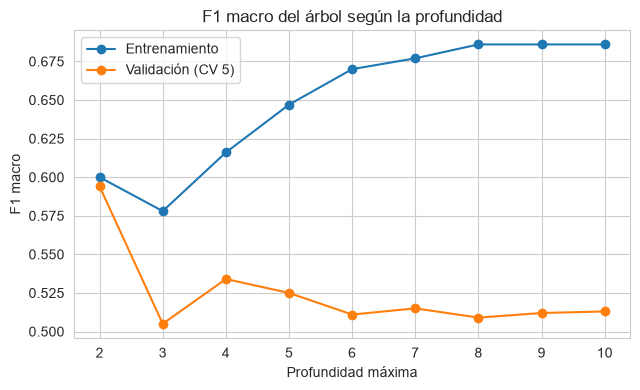

In [14]:
# Elección de la profundidad del árbol: SOLO validación cruzada sobre el entrenamiento (F1 macro)
filas = []
for prof in range(2, 11):
    pipe = Pipeline([("prep", prep(False)), ("m", DecisionTreeClassifier(max_depth=prof, min_samples_leaf=8, random_state=RANDOM_STATE))])
    r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring="f1_macro", return_train_score=True)
    filas.append({"profundidad": prof, "F1 macro entren.": r["train_score"].mean(),
                  "F1 macro validación": r["test_score"].mean(), "D.E. validación": r["test_score"].std()})
tabla_prof = pd.DataFrame(filas).set_index("profundidad").round(3)
tabla_prof["brecha"] = (tabla_prof["F1 macro entren."] - tabla_prof["F1 macro validación"]).round(3)
print(tabla_prof)

plt.figure(figsize=(6.5, 4))
plt.plot(tabla_prof.index, tabla_prof["F1 macro entren."], marker="o", label="Entrenamiento")
plt.plot(tabla_prof.index, tabla_prof["F1 macro validación"], marker="o", label="Validación (CV 5)")
plt.xlabel("Profundidad máxima"); plt.ylabel("F1 macro"); plt.title("F1 macro del árbol según la profundidad")
plt.legend(); plt.tight_layout(); plt.show()

**Interpretación.** El mayor F1 macro de validación se da con **profundidad 2** (0,594 ± 0,034) y es además donde la brecha entrenamiento–validación es mínima (0,006). Al aumentar la profundidad, el F1 de entrenamiento sube hasta 0,686 pero el de validación cae a ~0,51: **sobreajuste**. Se fija la profundidad en 2, decisión tomada solo con el entrenamiento.

In [15]:
PROF = int(tabla_prof["F1 macro validación"].idxmax())
print("Profundidad elegida (mayor F1 macro de validación):", PROF)

modelos = {
    "Regresión logística": Pipeline([("prep", prep(True)),
                                     ("m", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
    "Árbol de decisión":   Pipeline([("prep", prep(False)),
                                     ("m", DecisionTreeClassifier(max_depth=PROF, min_samples_leaf=8, random_state=RANDOM_STATE))]),
}

Profundidad elegida (mayor F1 macro de validación): 2


## 6. Entrenamiento y evaluación *(1.4 y 1.5)*

**Qué error importa más.** Clasificar a un paciente de riesgo **Alto** como Bajo es el error más grave; se sigue con especial atención el **recall de la clase Alto** y cuántos casos Alto se confunden con Bajo. No se elige el modelo solo por el *accuracy*.

In [16]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

res, preds = [], {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    yp = pipe.predict(X_test); preds[nombre] = yp
    k = int((yp == y_test).sum()); lo, hi = wilson(k, len(y_test))
    res.append({"Modelo": nombre,
                "Accuracy": accuracy_score(y_test, yp), "IC 95 % acc.": f"[{lo:.3f}; {hi:.3f}]",
                "Precision (macro)": precision_score(y_test, yp, average="macro"),
                "Recall (macro)": recall_score(y_test, yp, average="macro"),
                "F1 (macro)": f1_score(y_test, yp, average="macro"),
                "Recall Alto": recall_score(y_test, yp, labels=["Alto"], average=None)[0],
                "Accuracy entren.": pipe.score(X_train, y_train)})
tabla = pd.DataFrame(res).set_index("Modelo")
cols_num = [c for c in tabla.columns if c != "IC 95 % acc."]
tabla[cols_num] = tabla[cols_num].astype(float).round(3)
tabla

,Accuracy,IC 95 % acc.,Precision (macro),Recall (macro),F1 (macro),Recall Alto,Accuracy entren.
Modelo,,,,,,,
Regresión logística,0.674,[0.611; 0.731],0.601,0.599,0.572,0.849,0.657
Árbol de decisión,0.591,[0.527; 0.653],0.553,0.550,0.550,0.742,0.638


In [17]:
# Resultados por clase
for nombre, yp in preds.items():
    print(f"===== {nombre} =====")
    print(classification_report(y_test, yp, labels=ORDEN, digits=3))

===== Regresión logística =====
              precision    recall  f1-score   support

        Bajo      0.711     0.812     0.758        85
       Medio      0.412     0.135     0.203        52
        Alto      0.681     0.849     0.756        93

    accuracy                          0.674       230
   macro avg      0.601     0.599     0.572       230
weighted avg      0.631     0.674     0.632       230

===== Árbol de decisión =====
              precision    recall  f1-score   support

        Bajo      0.680     0.600     0.637        85
       Medio      0.296     0.308     0.302        52
        Alto      0.683     0.742     0.711        93

    accuracy                          0.591       230
   macro avg      0.553     0.550     0.550       230
weighted avg      0.595     0.591     0.591       230



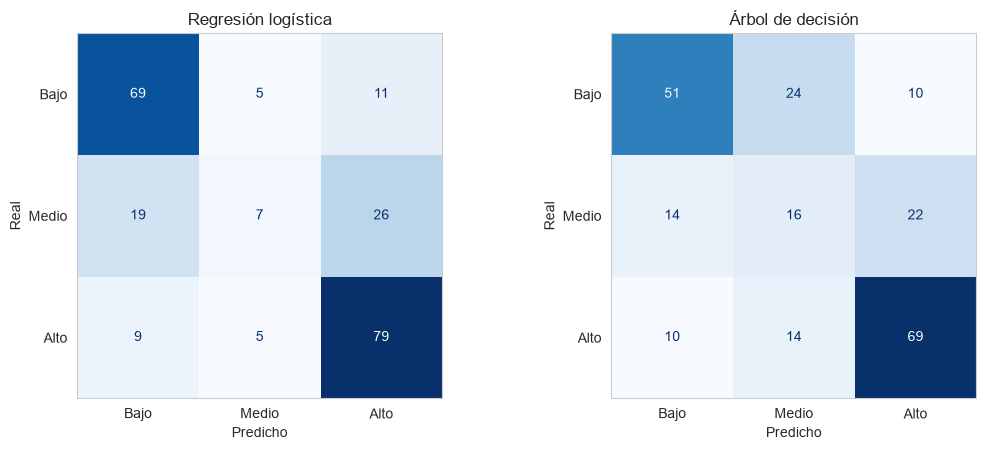

Regresión logística: errores totales = 75 | Alto→Bajo = 9 | Alto→Medio = 5 | Bajo→Alto = 11
Árbol de decisión: errores totales = 94 | Alto→Bajo = 10 | Alto→Medio = 14 | Bajo→Alto = 10


In [18]:
# Matrices de confusión (filas = real, columnas = predicho)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (nombre, yp) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, yp, labels=ORDEN), display_labels=ORDEN).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
plt.tight_layout(); plt.show()

for nombre, yp in preds.items():
    cm = pd.DataFrame(confusion_matrix(y_test, yp, labels=ORDEN), index=ORDEN, columns=ORDEN)
    print(f"{nombre}: errores totales = {int((yp != y_test).sum())} | "
          f"Alto→Bajo = {cm.loc['Alto','Bajo']} | Alto→Medio = {cm.loc['Alto','Medio']} | Bajo→Alto = {cm.loc['Bajo','Alto']}")

**Interpretación.**
* **Regresión logística:** accuracy 0,674 (IC 95 % de Wilson [0,611; 0,731]), F1 macro 0,572 y recall de Alto 0,849 (79 de 93). Tuvo 75 errores.
* **Árbol (profundidad 2):** accuracy 0,591 [0,527; 0,653], F1 macro 0,550 y recall de Alto 0,742 (69 de 93). Tuvo 94 errores.
* **Clase Medio:** es la más difícil para ambos: recall 0,135 (7 de 52) en la logística y 0,308 (16 de 52) en el árbol, con precisiones de 0,412 y 0,296. Es esperable: es una clase intermedia definida por combinaciones, y los predictores no incluyen las variables que la definen.
* **Errores graves (Alto clasificado como Bajo):** 9 en la logística y 10 en el árbol. Sin embargo, el árbol confunde 14 casos Alto con Medio frente a 5 de la logística.
* Los intervalos de confianza de ambos accuracy se solapan parcialmente, por lo que la diferencia no es concluyente por sí sola.

In [19]:
# Validación cruzada (5 pliegues) sobre el ENTRENAMIENTO
filas = []
for nombre, pipe in modelos.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=["accuracy", "f1_macro"])
    filas.append({"Modelo": nombre,
                  "Accuracy": f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
                  "F1 macro": f"{r['test_f1_macro'].mean():.3f} ± {r['test_f1_macro'].std():.3f}",
                  "Mínimo F1 macro": round(r['test_f1_macro'].min(), 3), "Máximo F1 macro": round(r['test_f1_macro'].max(), 3)})
pd.DataFrame(filas).set_index("Modelo")

,Accuracy,F1 macro,Mínimo F1 macro,Máximo F1 macro
Modelo,,,,
Regresión logística,0.642 ± 0.020,0.544 ± 0.008,0.530,0.556
Árbol de decisión,0.632 ± 0.024,0.594 ± 0.034,0.533,0.627


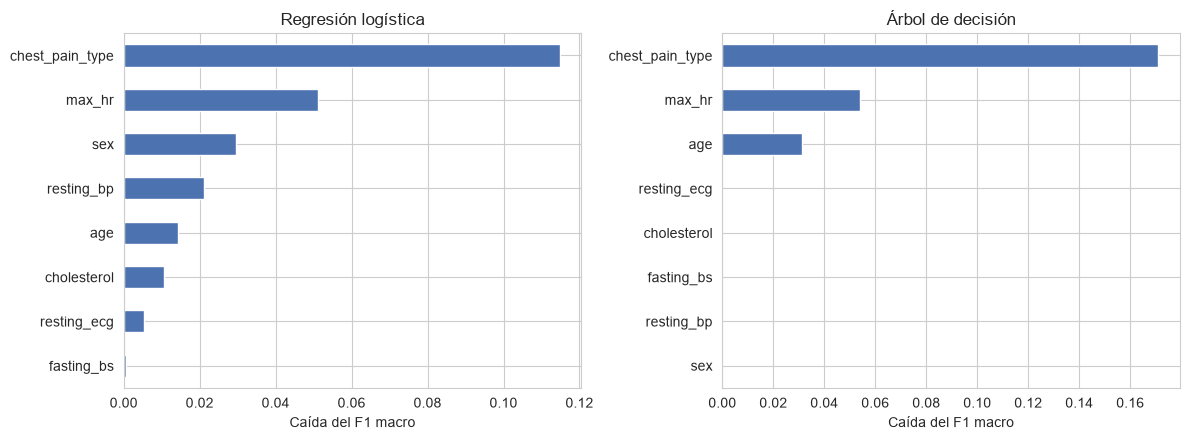

,Regresión logística,Árbol de decisión
chest_pain_type,0.115,0.171
max_hr,0.051,0.054
sex,0.030,0.000
resting_bp,0.021,0.000
age,0.014,0.031
cholesterol,0.011,0.000
resting_ecg,0.005,0.000
fasting_bs,0.001,0.000


In [20]:
# Importancia por permutación (caída del F1 macro en prueba, 30 repeticiones)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
imp_tab = {}
for ax, (nombre, pipe) in zip(axes, modelos.items()):
    r = permutation_importance(pipe, X_test, y_test, scoring="f1_macro", n_repeats=30, random_state=RANDOM_STATE)
    s = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
    imp_tab[nombre] = s.round(3)
    s.plot(kind="barh", ax=ax, color="#4C72B0"); ax.set_title(nombre); ax.set_xlabel("Caída del F1 macro")
plt.tight_layout(); plt.show()
pd.DataFrame(imp_tab).sort_values("Regresión logística", ascending=False)

**Interpretación.** En ambos modelos la variable más influyente es el **tipo de dolor torácico** (caída del F1 macro de 0,115 en la logística y 0,171 en el árbol), seguida de la **frecuencia cardíaca máxima** (0,051 y 0,054). El sexo (0,030) y la presión en reposo (0,021) aportan algo en la logística, mientras que el árbol, con solo dos niveles, no las usa. Colesterol, ECG en reposo y glucosa en ayunas casi no aportan. Esto coincide con el EDA, aunque la importancia por permutación mide el uso del modelo, no causalidad.

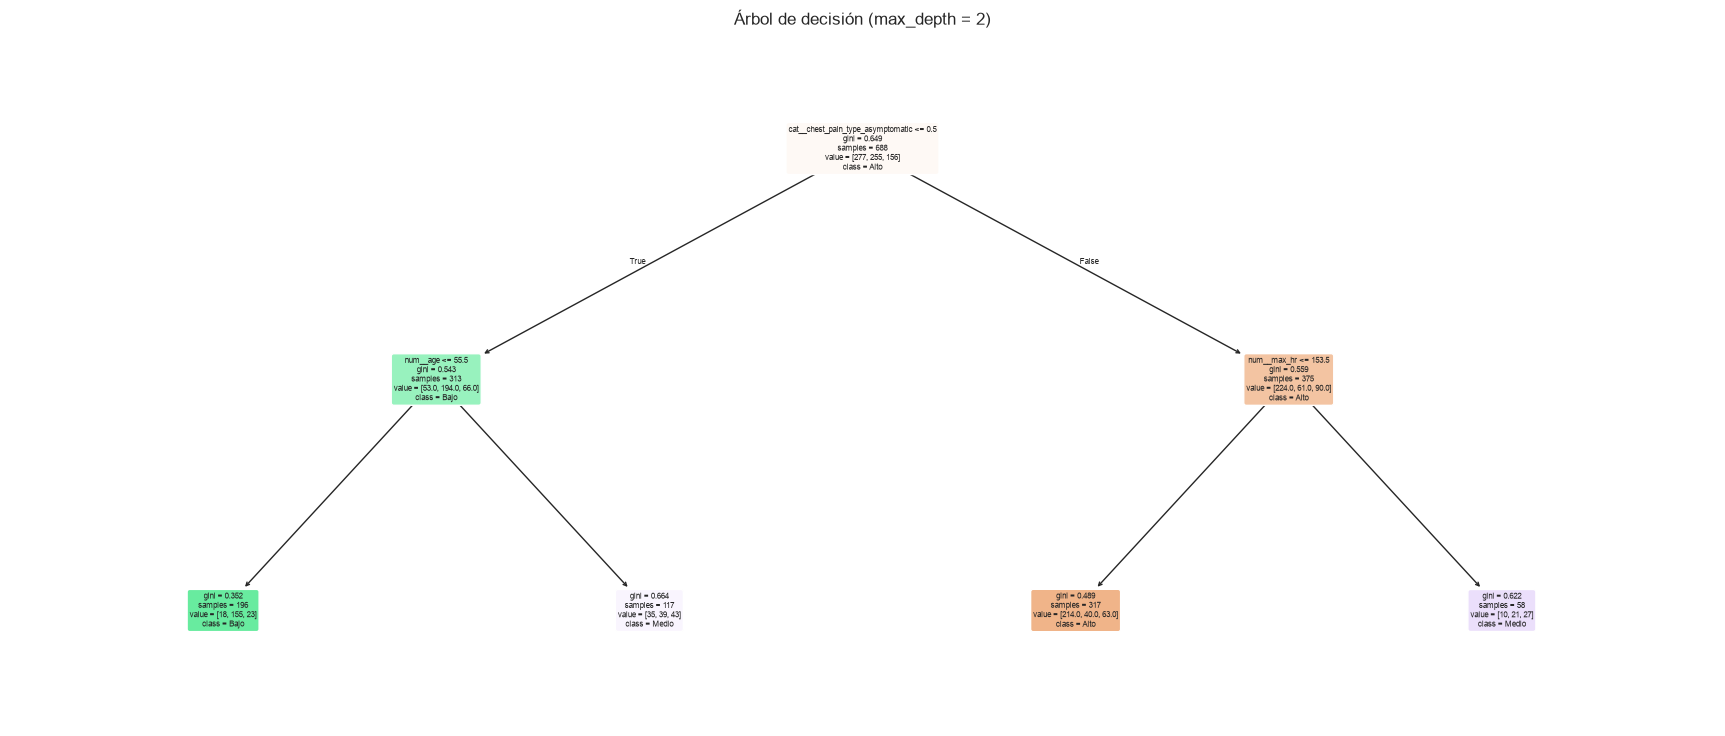

In [21]:
# Árbol de decisión
plt.figure(figsize=(22, 9))
plot_tree(modelos["Árbol de decisión"].named_steps["m"],
          feature_names=modelos["Árbol de decisión"].named_steps["prep"].get_feature_names_out(),
          class_names=modelos["Árbol de decisión"].named_steps["m"].classes_, filled=True, rounded=True, fontsize=6)
plt.title(f"Árbol de decisión (max_depth = {PROF})"); plt.show()

## 7. Análisis de sensibilidad: efecto de incluir las variables que construyen la etiqueta

Para dimensionar la fuga de información conceptual, se entrena la misma regresión logística **incluyendo** `exercise_angina`, `st_slope` y `oldpeak`.

In [22]:
pred_leak = pred_feats + ["exercise_angina", "st_slope", "oldpeak"]
Xl = df_limpio[pred_leak]
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
num_l = Xl.select_dtypes(include="number").columns.tolist(); cat_l = Xl.select_dtypes(exclude="number").columns.tolist()
pre_l = ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num_l),
                           ("cat", OneHotEncoder(handle_unknown="ignore"), cat_l)])
lr_l = Pipeline([("prep", pre_l), ("m", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]).fit(Xl_tr, yl_tr)
yl = lr_l.predict(Xl_te)
comp = pd.DataFrame({
    "Sin variables de la regla (modelo del estudio)": [accuracy_score(y_test, preds["Regresión logística"]), f1_score(y_test, preds["Regresión logística"], average="macro"), recall_score(y_test, preds["Regresión logística"], labels=["Alto"], average=None)[0]],
    "Con variables de la regla": [accuracy_score(yl_te, yl), f1_score(yl_te, yl, average="macro"), recall_score(yl_te, yl, labels=["Alto"], average=None)[0]]},
    index=["Accuracy", "F1 macro", "Recall Alto"]).round(3)
comp

,Sin variables de la regla (modelo del estudio),Con variables de la regla
Accuracy,0.674,0.857
F1 macro,0.572,0.825
Recall Alto,0.849,0.892


**Interpretación.** Al incluir `exercise_angina`, `st_slope` y `oldpeak`, el accuracy sube de 0,674 a 0,857, el F1 macro de 0,572 a 0,825 y el recall de Alto de 0,849 a 0,892. Esa mejora de ~18 puntos de accuracy refleja en gran parte la **recuperación de la regla** con la que se construyó la etiqueta y no un fenómeno real; por eso se excluyen de los predictores y el modelo del estudio es el más bajo.

## 8. Conclusiones del notebook *(1.6)*

**Hallazgos del EDA.** El dataset (918 × 12) tiene faltantes ocultos como cero (172 en colesterol, 1 en presión) y el faltante de colesterol no es aleatorio. El riesgo construido (Bajo 37,0 %, Medio 22,7 %, Alto 40,3 %) se asocia con mayor edad, menor frecuencia cardíaca máxima, dolor torácico asintomático y sexo masculino; las asociaciones con las variables predictoras son moderadas (|ρ| ≤ 0,46).

**Modelo más adecuado.** La **regresión logística** resultó más adecuada: mayor accuracy (0,674 frente a 0,591), mayor recall de Alto (0,849 frente a 0,742), menos errores totales (75 frente a 94) y menos casos Alto clasificados como Medio (5 frente a 14). El árbol de profundidad 2 la supera en F1 macro en validación cruzada (0,594 frente a 0,544) y en recall de la clase Medio, por lo que **no hay un ganador absoluto**; la elección se apoya en el error que más importa (Alto) y en la interpretabilidad.

**Evidencias.** Tabla de métricas con intervalos de Wilson, resultados por clase, matrices de confusión, validación cruzada, importancia por permutación y análisis de sensibilidad.

**Errores y limitaciones.** (1) La etiqueta `nivel_riesgo` fue construida por el grupo con una regla propia, no es un riesgo clínico validado y su regla es arbitraria. (2) La clase Medio apenas se predice (recall 0,135 y 0,308). (3) Desempeño moderado (F1 macro ≈ 0,55–0,57) porque se excluyeron los predictores que definen la etiqueta. (4) Faltantes de colesterol no aleatorios imputados con la mediana. (5) Prueba de 230 pacientes y solo 193 mujeres en el dataset. (6) Sin ajuste de hiperparámetros ni validación externa. **Los resultados no son criterios ni recomendaciones médicas.**

**Para el tercer corte:** revisar o validar la regla de construcción del riesgo, probar otras definiciones del nivel Medio, evaluar modelos adicionales y ajuste de hiperparámetros, y redactar el artículo final.

## Tercer corte: integración y despliegue

### Tercer corte: revisión del modelo (antes / después)

Se compara el modelo del segundo corte con una variante con `class_weight="balanced"` (la clase Medio casi no se detectaba, recall 0.135) y con el árbol. Criterios: recall de Alto, errores Alto→Bajo, recall de Medio, F1 macro y estabilidad en validación cruzada; no solo el accuracy.

In [ ]:
import os, json, joblib
from sklearn.base import clone

os.makedirs("artefactos", exist_ok=True)

candidatos = {
    "Regresión logística (corte 2)": modelos["Regresión logística"],
    "Regresión logística (class_weight=balanced)": Pipeline([
        ("prep", prep(True)),
        ("m", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Árbol de decisión (prof. 2)": modelos["Árbol de decisión"],
}

filas = []
for nombre, pipe in candidatos.items():
    p = clone(pipe)
    cv = cross_validate(p, X_train, y_train, cv=cv5, scoring=["accuracy", "f1_macro"])
    p.fit(X_train, y_train)
    yp = p.predict(X_test)
    cm = pd.DataFrame(confusion_matrix(y_test, yp, labels=ORDEN), index=ORDEN, columns=ORDEN)
    filas.append({
        "Modelo": nombre,
        "CV accuracy": f"{cv['test_accuracy'].mean():.3f} ± {cv['test_accuracy'].std():.3f}",
        "CV F1 macro": f"{cv['test_f1_macro'].mean():.3f} ± {cv['test_f1_macro'].std():.3f}",
        "Test accuracy": round(accuracy_score(y_test, yp), 3),
        "Test F1 macro": round(f1_score(y_test, yp, average="macro"), 3),
        "Recall Alto": round(recall_score(y_test, yp, labels=["Alto"], average=None)[0], 3),
        "Recall Medio": round(recall_score(y_test, yp, labels=["Medio"], average=None)[0], 3),
        "Alto→Bajo": int(cm.loc["Alto", "Bajo"]),
    })
comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion

### Elección del modelo final y guardado del pipeline

**Decisión:** completar con la justificación del grupo tras ver la tabla anterior. El pipeline final se entrena solo con el conjunto de entrenamiento y se guarda con joblib junto con las métricas y los registros de prueba usados en la app.

In [ ]:
# Elige el modelo mirando la tabla anterior: prioriza recall de Alto y pocos Alto→Bajo,
# y la estabilidad en CV; no solo el accuracy. Escribe aquí la justificación.
MODELO_FINAL = "Regresión logística (class_weight=balanced)"   # alternativa: "Regresión logística (corte 2)"

final = clone(candidatos[MODELO_FINAL]).fit(X_train, y_train)   # solo entrenamiento
yp = final.predict(X_test)

k = int((yp == y_test).sum()); lo, hi = wilson(k, len(y_test))
rep = classification_report(y_test, yp, labels=ORDEN, output_dict=True, zero_division=0)
cv = cross_validate(clone(candidatos[MODELO_FINAL]), X_train, y_train, cv=cv5, scoring=["accuracy", "f1_macro"])

metricas = {
    "modelo": MODELO_FINAL,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "accuracy": float(accuracy_score(y_test, yp)), "ic95": [float(lo), float(hi)],
    "precision_macro": float(precision_score(y_test, yp, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_test, yp, average="macro")),
    "f1_macro": float(f1_score(y_test, yp, average="macro")),
    "por_clase": {c: {"precision": float(rep[c]["precision"]), "recall": float(rep[c]["recall"]),
                      "f1": float(rep[c]["f1-score"]), "support": int(rep[c]["support"])} for c in ORDEN},
    "orden": ORDEN,
    "matriz": confusion_matrix(y_test, yp, labels=ORDEN).tolist(),
    "cv": {"accuracy_mean": float(cv["test_accuracy"].mean()), "accuracy_std": float(cv["test_accuracy"].std()),
           "f1_mean": float(cv["test_f1_macro"].mean()), "f1_std": float(cv["test_f1_macro"].std())},
    "comparacion": comparacion.reset_index().to_dict(orient="records"),
}

joblib.dump(final, "artefactos/modelo_riesgo.joblib")
json.dump(metricas, open("artefactos/metricas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

# Registros de prueba con la predicción del notebook (para la verificación en la app)
muestra = X_test.copy()
muestra["real"] = y_test.values
muestra["pred_notebook"] = yp
muestra.to_csv("artefactos/muestra_prueba.csv", index_label="id_registro")

# Datos para los gráficos del EDA (sin información personal: dataset público de Kaggle)
df_limpio[pred_feats + ["nivel_riesgo"]].to_csv("artefactos/datos_eda.csv", index=False)
print("Guardado en ./artefactos:", os.listdir("artefactos"))

### Comprobación del archivo guardado

El pipeline guardado debe reproducir las predicciones del notebook; se anota la versión de scikit-learn para `requirements.txt`.

In [ ]:
cargado = joblib.load("artefactos/modelo_riesgo.joblib")
assert (cargado.predict(X_test) == yp).all(), "El pipeline guardado no reproduce las predicciones"
print("OK: el pipeline cargado coincide con el del notebook en los", len(X_test), "registros de prueba.")
import sklearn; print("Versión de scikit-learn (fíjala en requirements.txt):", sklearn.__version__)